# AVAX LONG — Bollinger + RSI, **nhiều lệnh chồng nhau**, train full grid trên GPU

Notebook này dùng `train_full_grid_gpu.py` cùng thư mục (logic chung ở `reference/multi_position/multi_position_engine.py`). Sửa **ô Cấu hình**, rồi chọn **Run All**. Kết quả lưu thành CSV cạnh notebook.

**Vào lệnh tại nến `i`:** `close[i-1] < upper[i] < close[i]` **và** `RSI(rsi_window)[i] > rsi_threshold`. **Risk:** `sl_multiplier × (entry − lower[i])`; stop = entry − risk, TP = entry + `tp_sl_ratio` × risk. Timeout `MAX_HOLDING_BARS` nến; phí vào lệnh `0.001 / sl_ratio` (bỏ lệnh nếu > 0.2R); phí giữ lệnh `0.0001 × (số nến / FEE_BARS) / sl_ratio`.

**Khác bản gốc `reference/long_bollinger+RSI`:** bản gốc giữ **một lệnh** và bỏ mọi tín hiệu xuất hiện khi lệnh đang mở. Ở đây **mỗi tín hiệu mở một lệnh riêng**; mỗi lệnh có stop/TP/timeout riêng, đóng độc lập. Tại mỗi nến: (1) xét tín hiệu, (2) xét thoát cho các lệnh đang mở (timeout → stop → TP → hết dữ liệu), (3) thêm lệnh mới (bắt đầu xét thoát từ nến sau). `MAX_OPEN` giới hạn số lệnh mở cùng lúc (tối đa 64); **`MAX_OPEN = 1` cho kết quả trùng tuyệt đối bản gốc** (cùng phí).

**Đọc kết quả:** R tính **cho mỗi lệnh**. Khi N lệnh mở cùng lúc, rủi ro thực là N·R, nên R/tháng của bản nhiều lệnh không so thẳng được với bản 1 lệnh. Các cột thêm: `mtm_max_dd` (drawdown khi định giá cả lệnh đang mở theo close mỗi nến), `max_concurrent` / `avg_concurrent` (số lệnh mở tối đa / trung bình mỗi nến), `skipped_entries` (tín hiệu bị bỏ vì đã đủ `MAX_OPEN`). Ô so sánh đặt cạnh `r_per_month / max_concurrent` — lợi nhuận nếu chia vốn rủi ro cho số lệnh tối đa.

**Phí giữ lệnh:** mỗi 8 giờ (`FEE_BARS = None` ⇒ 32 ở 15min). Bản long gốc dùng 8 ở 15min (gấp 4 lần phía short); ở đây đã chuẩn hoá về 32 như các logic long mới. Grid search trên toàn khoảng train là **in-sample**; đánh giá ngoài mẫu bằng `reference/walk_forward_15min.py --folders multi_position/long_bollinger+RSI`.

In [24]:
# CẤU HÌNH — sửa ô này trước khi chạy
TIMEFRAME = "15min"                 # ví dụ "5min", "15min", "1h", "4h"
START_DATE = "2023-07-01"          # ngày bắt đầu, bao gồm ngày này
END_DATE = "2025-01-01"            # ngày kết thúc, bao gồm ngày này
DATA_CSV = None                     # None = CSV 5min của thư mục long_bollinger+RSI gốc
SCRIPT_PATH = None                  # None = tự tìm train_full_grid_gpu.py

SCORE_FORMULA = "performance/max_dd*r2**5"
# Sửa trực tiếp các danh sách dưới đây để đổi grid. Số bộ tham số là tích số giá trị mỗi danh sách.
SEARCH_SPACES = {
    "boll_window": [6, 7, 8, 10, 12, 14, 16, 18, 20, 25, 30, 35, 40, 45, 50],
    "boll_window_dev": [1.7, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8],
    "rsi_window": [30, 35, 40, 45, 50, 60, 80],
    "rsi_threshold": [50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70],
    "sl_multiplier": [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0],
    "tp_sl_ratio": [1.1],
}
LIMIT = None                         # None = toàn bộ bộ tham số; số nguyên để chạy thử
MAX_HOLDING_BARS = 288             # số nến tối đa giữ lệnh theo TIMEFRAME
MAX_OPEN = 64                       # số lệnh mở cùng lúc tối đa (1 = bản gốc một lệnh; tối đa 64)
FEE_BARS = None                    # None = 8 giờ mỗi lần phí (32 ở 15min)
VERIFY_SAMPLES = 0                  # 0 = bỏ qua so với CPU; ví dụ 8 = kiểm tra 8 bộ
MIN_TRADES = 50                     # bảng xếp hạng chỉ giữ bộ có nhiều lệnh hơn số này
OUTPUT_CSV = None                   # None = CSV theo timeframe, cạnh notebook

In [25]:
# Nạp script cùng thư mục (cũng hoạt động khi kernel bắt đầu ở thư mục khác trong repo)
from pathlib import Path
import importlib.util
import itertools
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SIDE_FOLDER = "long_bollinger+RSI"
if SCRIPT_PATH is None:
    candidates = []
    for parent in (Path.cwd(), *Path.cwd().parents):
        if parent.name == SIDE_FOLDER and parent.parent.name == "multi_position":
            candidates.append(parent / "train_full_grid_gpu.py")
        candidates.append(parent / "multi_position" / SIDE_FOLDER / "train_full_grid_gpu.py")
        candidates.append(parent / "reference" / "multi_position" / SIDE_FOLDER / "train_full_grid_gpu.py")
    script_path = next((path.resolve() for path in candidates if path.is_file()), None)
    if script_path is None:
        raise FileNotFoundError("Không tìm thấy train_full_grid_gpu.py; hãy đặt SCRIPT_PATH ở ô Cấu hình")
else:
    script_path = Path(SCRIPT_PATH).expanduser().resolve()
if not script_path.is_file():
    raise FileNotFoundError(script_path)

spec = importlib.util.spec_from_file_location("avax_multi_long_bollinger_RSI", script_path)
strategy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(strategy)
csv_path = Path(DATA_CSV).expanduser().resolve() if DATA_CSV else strategy.DEFAULT_CSV
if not csv_path.is_file():
    raise FileNotFoundError(csv_path)
if not 1 <= MAX_OPEN <= strategy.MAX_SLOTS:
    raise ValueError(f"MAX_OPEN phải trong khoảng 1..{strategy.MAX_SLOTS}")
print("CSV:", csv_path)
print("Đã nạp:", script_path)
print("Phí giữ lệnh: mỗi", strategy.resolve_fee_bars(TIMEFRAME, FEE_BARS), "nến; MAX_OPEN =", MAX_OPEN)

CSV: C:\Users\Legion\Desktop\TradingProject\reference\long_bollinger+RSI\avaxusdt_futures_5min.csv
Đã nạp: C:\Users\Legion\Desktop\TradingProject\reference\multi_position\long_bollinger+RSI\train_full_grid_gpu.py
Phí giữ lệnh: mỗi 32.0 nến; MAX_OPEN = 64


In [26]:
# Đọc dữ liệu 5 phút, resample và tạo grid
strategy.timeframe_nanos(TIMEFRAME)
start_date, end_date = START_DATE, END_DATE
expected_keys = set(strategy.SEARCH_SPACE)
space = SEARCH_SPACES
if set(space) != expected_keys:
    raise ValueError(f"SEARCH_SPACES cần đúng các khóa: {sorted(expected_keys)}")
for name, values in space.items():
    if not isinstance(values, (list, tuple)) or not values:
        raise ValueError(f"{name} phải là danh sách có ít nhất một giá trị")
space = {name: list(values) for name, values in space.items()}

bars = strategy.load_bars(csv_path, TIMEFRAME, start_date, end_date)
combinations = itertools.product(*(space[name] for name in space))
if LIMIT is not None:
    combinations = itertools.islice(combinations, LIMIT)
grid = pd.DataFrame(combinations, columns=list(space))
print(f"Dữ liệu: {len(bars):,} nến; {bars['timestamp'].iloc[0]} → {bars['timestamp'].iloc[-1]}")
print(f"Grid: {len(grid):,} bộ tham số")
display(grid.head())

Dữ liệu: 52,896 nến; 2023-07-01 00:00:00 → 2025-01-01 23:45:00
Grid: 370,440 bộ tham số


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio
0,6,1.7,30,50,0.7,1.1
1,6,1.7,30,50,0.8,1.1
2,6,1.7,30,50,0.9,1.1
3,6,1.7,30,50,1.0,1.1
4,6,1.7,30,50,1.1,1.1


In [27]:
# Chạy toàn bộ grid trên GPU
result, timing = strategy.run_gpu_grid(
    bars, grid, TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS,
    fee_bars=FEE_BARS,
    score_formula=SCORE_FORMULA,
    max_open=MAX_OPEN,
)
print("Thời gian:", timing)
print(f"Đã tính {len(result):,} bộ tham số")
print(f"Lệnh mở cùng lúc: tối đa {result['max_concurrent'].max()}, trung vị của max {result['max_concurrent'].median():g}; "
      f"tín hiệu bị bỏ vì đủ MAX_OPEN: {int(result['skipped_entries'].sum()):,}")

Thời gian: {'indicators_and_transfer_s': 0.7705805000150576, 'holding_fee_bars': 32.0, 'total_gpu_s': 7.230297100031748}
Đã tính 370,440 bộ tham số
Lệnh mở cùng lúc: tối đa 26, trung vị của max 7; tín hiệu bị bỏ vì đủ MAX_OPEN: 0


In [28]:
# TÍNH LẠI SCORE — chạy lại riêng ô này sau khi đổi SCORE_FORMULA
result = strategy.score_result(result, SCORE_FORMULA)
print("Score:", SCORE_FORMULA)

Score: performance/max_dd*r2**5


In [29]:
# Kiểm tra CPU (tùy chọn): đối chiếu mẫu với replay float64
# Có thể lệch rất ít bộ khi giá chạm dải/stop sát ngưỡng làm tròn fp32 (đã gặp ở bản short gốc).
if VERIFY_SAMPLES:
    strategy.verify_samples(bars, result, VERIFY_SAMPLES, MAX_HOLDING_BARS, FEE_BARS, TIMEFRAME, MAX_OPEN)

In [30]:
# Lưu kết quả và xem các bộ tham số đứng đầu
output_path = (Path(OUTPUT_CSV).expanduser().resolve() if OUTPUT_CSV
               else script_path.with_name(f"full_gpu_grid_results_{TIMEFRAME}_fp32.csv"))
output_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(output_path, index=False)

ranked = result.loc[(result["number_of_trade"] > MIN_TRADES) & result["score"].notna()].sort_values("score", ascending=False)

print("Đã lưu:", output_path)
print(f"Bộ có score hợp lệ và > {MIN_TRADES} lệnh: {len(ranked):,}/{len(result):,}")
display(ranked.head(20))

Đã lưu: C:\Users\Legion\Desktop\TradingProject\reference\multi_position\long_bollinger+RSI\full_gpu_grid_results_15min_fp32.csv
Bộ có score hợp lệ và > 50 lệnh: 276,543/370,440


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,...,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,avg_concurrent,number_of_trade,max_concurrent,skipped_entries,score,score_formula
345001,45,2.8,50,59,2.0,1.1,56.537022,5.14,1.07,0.914462,...,2.070949,1.508066,0.704044,8.376914,1.428426,303,11,0,7.033940,performance/max_dd*r2**5
31377,7,2.0,35,65,1.0,1.1,36.240986,4.15,1.02,0.956783,...,1.243610,1.609802,0.682243,4.197916,0.154057,136,4,0,7.001939,performance/max_dd*r2**5
298276,40,1.7,80,61,1.3,1.1,58.612995,5.21,0.68,0.907121,...,1.866002,1.735156,0.750292,9.486415,0.400087,113,11,0,6.910063,performance/max_dd*r2**5
58130,8,2.1,35,65,0.9,1.1,27.306522,3.17,1.10,0.956410,...,1.084612,1.390748,0.543517,3.997358,0.133261,119,3,0,6.893320,performance/max_dd*r2**5
298278,40,1.7,80,61,1.5,1.1,54.719116,4.91,0.58,0.907593,...,1.697629,1.780546,0.835637,10.359169,0.460848,113,11,0,6.862994,performance/max_dd*r2**5
344999,45,2.8,50,59,1.8,1.1,55.951374,5.29,1.20,0.916723,...,2.274947,1.358614,0.675350,9.961773,1.370860,303,11,0,6.847705,performance/max_dd*r2**5
31376,7,2.0,35,65,0.9,1.1,33.602581,4.17,1.07,0.963773,...,1.438560,1.290332,0.604244,4.219494,0.131314,136,3,0,6.700543,performance/max_dd*r2**5
298282,40,1.7,80,61,1.9,1.1,51.537628,4.79,0.51,0.907057,...,1.488400,1.912764,0.839294,9.484993,0.504159,113,11,0,6.606366,performance/max_dd*r2**5
298277,40,1.7,80,61,1.4,1.1,54.971954,5.12,0.68,0.907245,...,1.800870,1.686225,0.782096,10.041279,0.432622,113,11,0,6.599240,performance/max_dd*r2**5
298275,40,1.7,80,61,1.2,1.1,58.429585,5.47,0.73,0.904742,...,2.012425,1.603872,0.743433,10.164103,0.389387,113,11,0,6.475457,performance/max_dd*r2**5


In [31]:
# So với bản MỘT lệnh (MAX_OPEN = 1 = bản gốc) trên cùng grid, cùng dữ liệu, cùng phí
one, _ = strategy.run_gpu_grid(bars, grid, TIMEFRAME, max_holding_bars=MAX_HOLDING_BARS,
                               fee_bars=FEE_BARS, score_formula=SCORE_FORMULA, max_open=1)


def summary(frame):
    ok = frame["number_of_trade"] > MIN_TRADES
    f = frame[ok]
    return pd.Series({
        "số bộ > MIN_TRADES": int(ok.sum()),
        "số lệnh (trung vị)": f["number_of_trade"].median(),
        "R/tháng (trung vị)": f["r_per_month"].median(),
        "% bộ có lãi": (f["performance"] > 0).mean(),
        "max DD đã chốt (trung vị, R)": f["max_dd"].median(),
        "max DD MTM (trung vị, R)": f["mtm_max_dd"].median(),
        "Martin (trung vị)": f["r_martin_monthly"].median(),
        "lệnh mở tối đa (trung vị)": f["max_concurrent"].median(),
        "lệnh mở trung bình (trung vị)": f["avg_concurrent"].median(),
        "R/tháng ÷ lệnh mở tối đa (trung vị)": (f["r_per_month"] / f["max_concurrent"].clip(lower=1)).median(),
        "R/tháng ÷ max DD MTM (trung vị)": (f["r_per_month"] / f["mtm_max_dd"]).median(),
    })


comparison = pd.DataFrame({"1 lệnh (gốc)": summary(one), f"nhiều lệnh (MAX_OPEN={MAX_OPEN})": summary(result)})
display(comparison.round(3))
both = (one["number_of_trade"] > MIN_TRADES) & (result["number_of_trade"] > MIN_TRADES)
print(f"Cùng bộ tham số: nhiều lệnh có R/tháng cao hơn ở {(result.loc[both, 'r_per_month'] > one.loc[both, 'r_per_month']).mean():.1%} bộ; "
      f"Martin cao hơn ở {(result.loc[both, 'r_martin_monthly'] > one.loc[both, 'r_martin_monthly']).mean():.1%} bộ")
print(f"Tương quan hạng score giữa hai bản: {result.loc[both, 'score'].corr(one.loc[both, 'score'], method='spearman'):.3f}")

,1 lệnh (gốc),nhiều lệnh (MAX_OPEN=64)
số bộ > MIN_TRADES,238157.000,276543.000
số lệnh (trung vị),168.000,464.000
R/tháng (trung vị),0.231,1.119
% bộ có lãi,0.641,0.849
"max DD đã chốt (trung vị, R)",12.520,29.690
"max DD MTM (trung vị, R)",13.244,32.024
Martin (trung vị),0.047,0.112
lệnh mở tối đa (trung vị),1.000,9.000
lệnh mở trung bình (trung vị),0.346,0.947
R/tháng ÷ lệnh mở tối đa (trung vị),0.231,0.147


Cùng bộ tham số: nhiều lệnh có R/tháng cao hơn ở 83.6% bộ; Martin cao hơn ở 70.1% bộ
Tương quan hạng score giữa hai bản: 0.614


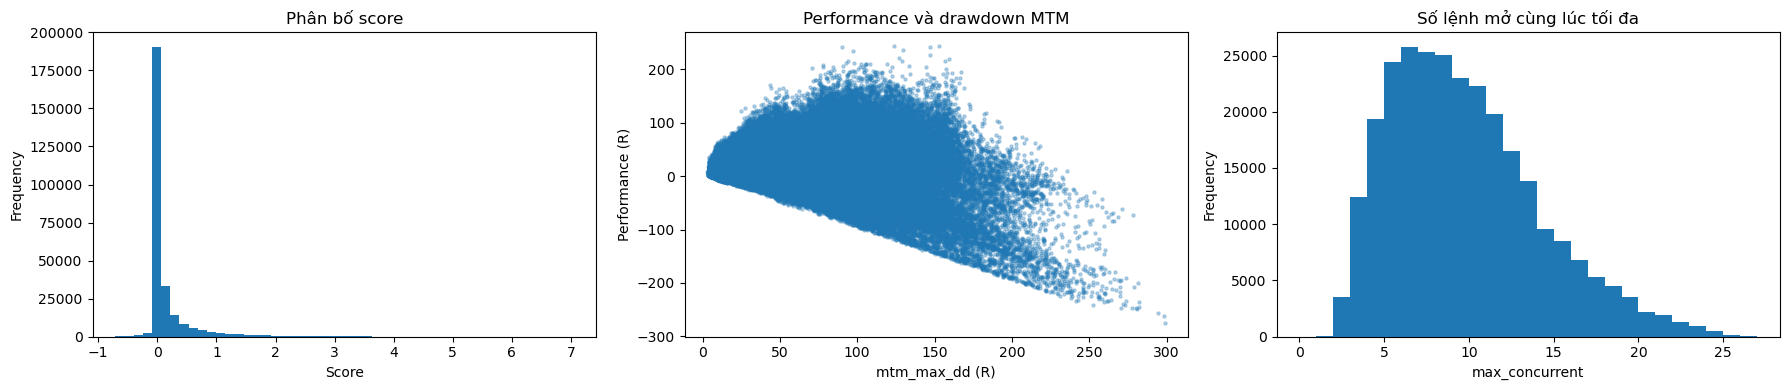

In [32]:
# Biểu đồ: phân bố score, hiệu quả theo drawdown MTM, và số lệnh mở cùng lúc
if ranked.empty:
    print("Không có score hợp lệ để vẽ")
else:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    ranked["score"].plot.hist(ax=axes[0], bins=50, title="Phân bố score")
    axes[0].set_xlabel("Score")
    axes[1].scatter(ranked["mtm_max_dd"], ranked["performance"], s=5, alpha=0.3)
    axes[1].set(xlabel="mtm_max_dd (R)", ylabel="Performance (R)", title="Performance và drawdown MTM")
    ranked["max_concurrent"].plot.hist(ax=axes[2], bins=range(0, int(ranked["max_concurrent"].max()) + 2),
                                       title="Số lệnh mở cùng lúc tối đa")
    axes[2].set_xlabel("max_concurrent")
    plt.tight_layout()
    plt.show()

Giai đoạn backtest: 2023-07-01 00:00:00 đến 2025-06-20 12:45:00


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,...,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,avg_concurrent,number_of_trade,max_concurrent,skipped_entries,score,score_formula
backtest_trial,45,2.8,50,59,2.0,1.1,49.814232,17.32,2.46,0.801304,...,5.181412,0.406118,0.490992,20.214954,1.307292,366,11,0,0.950149,performance/max_dd*r2**5


,performance,max_dd,avg_dd,r2,number_of_trade,r_per_month,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,max_concurrent,avg_concurrent,skipped_entries
nhiều lệnh (MAX_OPEN=64),49.814238,17.32,2.46,0.801303,366.0,2.104266,5.181415,0.406118,0.490992,20.214959,11.0,1.307292,0.0
1 lệnh (gốc),13.802316,5.31,1.02,0.821754,104.0,0.583041,1.662711,0.350657,0.375382,6.233360,1.0,0.360305,262.0


,số lệnh
outcome,
timeout,247
take_profit,83
stop,36


,entry_index,entry_timestamp,exit_index,close_timestamp,entry_price,risk,stop_loss,take_profit,holding_bars,open_at_entry,outcome,gross_r,entry_fee,holding_fee,net_r
0,674,2023-07-08 00:30:00,726,2023-07-08 13:30:00,12.930,0.807497,12.122503,13.818247,52,3,take_profit,1.100000,0.016012,0.002602,1.081386
1,676,2023-07-08 01:00:00,726,2023-07-08 13:30:00,12.915,0.842072,12.072928,13.841279,50,4,take_profit,1.100000,0.015337,0.002396,1.082266
2,677,2023-07-08 01:15:00,780,2023-07-09 03:00:00,12.975,1.008877,11.966123,14.084765,103,5,take_profit,1.100000,0.012861,0.004140,1.083000
3,515,2023-07-06 08:45:00,803,2023-07-09 08:45:00,13.027,1.242601,11.784399,14.393861,288,1,timeout,0.822468,0.010484,0.009435,0.802549
4,516,2023-07-06 09:00:00,804,2023-07-09 09:00:00,13.060,1.356619,11.703381,14.552281,288,2,timeout,0.668574,0.009627,0.008664,0.650283
5,684,2023-07-08 03:00:00,972,2023-07-11 03:00:00,13.288,1.863309,11.424691,15.337640,288,6,timeout,0.185154,0.007131,0.006418,0.171605
6,686,2023-07-08 03:30:00,974,2023-07-11 03:30:00,13.239,1.854767,11.384233,15.279244,288,7,timeout,0.198408,0.007138,0.006424,0.184846
7,687,2023-07-08 03:45:00,975,2023-07-11 03:45:00,13.333,2.119736,11.213264,15.664709,288,8,timeout,0.140584,0.006290,0.005661,0.128633
8,688,2023-07-08 04:00:00,976,2023-07-11 04:00:00,13.377,2.281516,11.095484,15.886668,288,9,timeout,0.124040,0.005863,0.005277,0.112900
9,779,2023-07-09 02:45:00,1067,2023-07-12 02:45:00,14.016,1.265829,12.750171,15.408412,288,8,timeout,-0.631997,0.011073,0.009965,-0.653035


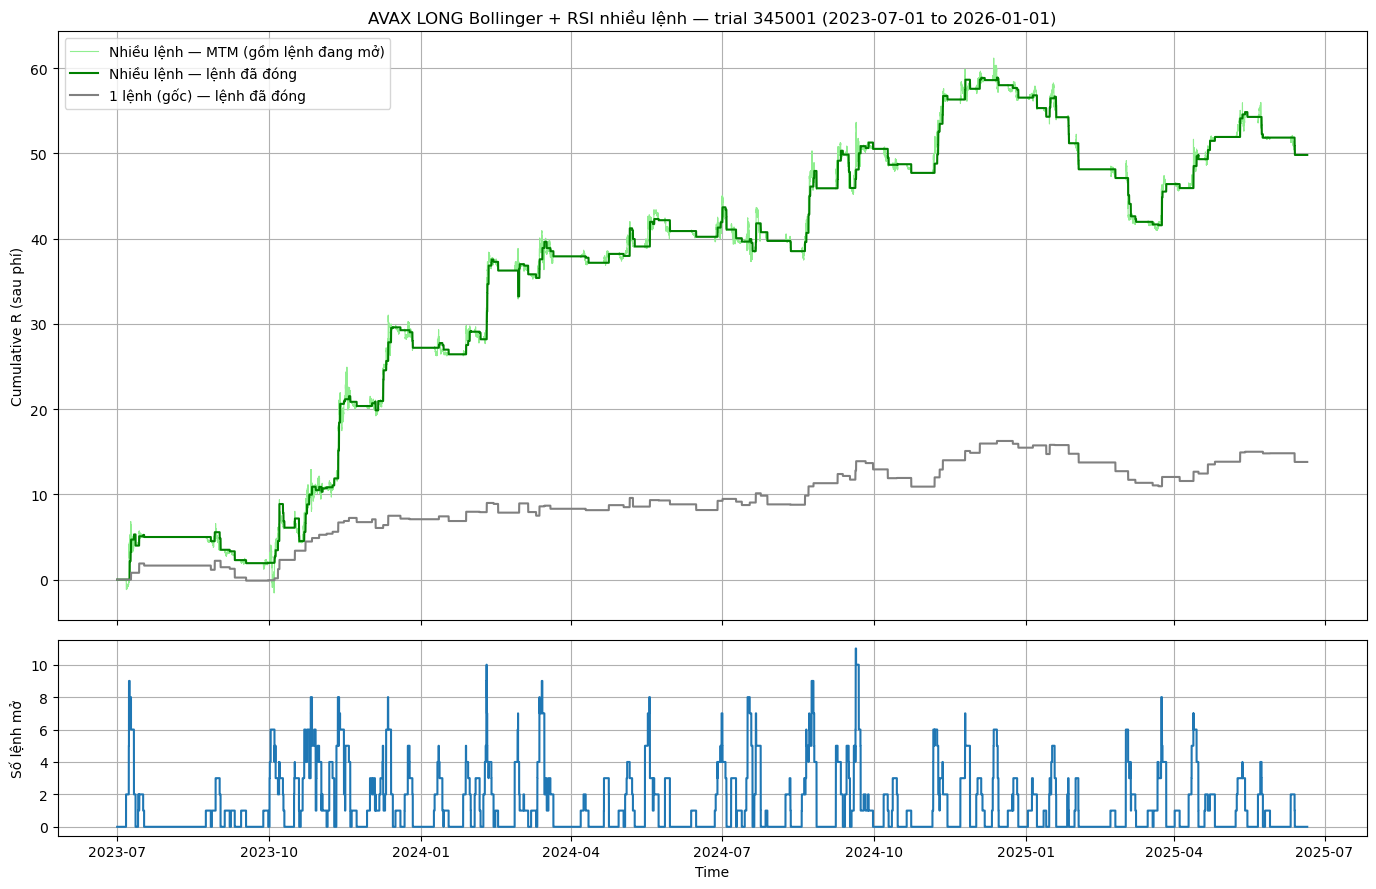

In [33]:
# Điền ID của trial trong bảng `result` (đếm từ 0), rồi chạy riêng ô này. None = bộ đứng đầu `ranked`.
TRIAL_ID = None
BACKTEST_START_DATE = None  # Ví dụ "2024-07-01"; None = ngày bắt đầu train
BACKTEST_END_DATE = "2026-01-01"    # Ví dụ "2025-06-20"; None = ngày kết thúc train

import numpy as np

if TRIAL_ID is None:
    if ranked.empty:
        raise ValueError("Bảng ranked rỗng; hãy điền TRIAL_ID")
    TRIAL_ID = int(ranked.index[0])
if TRIAL_ID not in result.index:
    raise KeyError(f"TRIAL_ID={TRIAL_ID} không có trong result.index")
params = grid.loc[TRIAL_ID].to_dict()
backtest_start = BACKTEST_START_DATE or start_date
backtest_end = BACKTEST_END_DATE or end_date
backtest_bars = (bars if BACKTEST_START_DATE is None and BACKTEST_END_DATE is None
                 else strategy.load_bars(csv_path, TIMEFRAME, backtest_start, backtest_end))

# GPU cho đúng một bộ tham số, và replay float64 liệt kê từng lệnh; hai bên phải khớp.
backtest_result, _ = strategy.run_gpu_grid(
    backtest_bars, grid.loc[[TRIAL_ID]].reset_index(drop=True), TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS, fee_bars=FEE_BARS, score_formula=SCORE_FORMULA, max_open=MAX_OPEN)
backtest_trial = backtest_result.iloc[0]
trades = strategy.cpu_trace(backtest_bars, params, TIMEFRAME, MAX_HOLDING_BARS, FEE_BARS, MAX_OPEN)
replay = strategy.trade_metrics(backtest_bars, trades, TIMEFRAME, FEE_BARS)
if replay["number_of_trade"] != int(backtest_trial["number_of_trade"]):
    print(f"Lưu ý: GPU {int(backtest_trial['number_of_trade'])} lệnh, replay float64 {replay['number_of_trade']} "
          "(giá sát ngưỡng làm tròn fp32)")
single = strategy.cpu_trace(backtest_bars, params, TIMEFRAME, MAX_HOLDING_BARS, FEE_BARS, 1)
single_metrics = strategy.trade_metrics(backtest_bars, single, TIMEFRAME, FEE_BARS)

print(f"Giai đoạn backtest: {backtest_bars['timestamp'].iloc[0]} đến {backtest_bars['timestamp'].iloc[-1]}")
display(backtest_trial.to_frame(name="backtest_trial").T)
display(pd.DataFrame({f"nhiều lệnh (MAX_OPEN={MAX_OPEN})": replay, "1 lệnh (gốc)": single_metrics}).T)
display(trades["outcome"].value_counts().to_frame("số lệnh"))
display(trades.head(20))

if trades.empty:
    print("Không có lệnh nào trong khoảng backtest")
else:
    equity = strategy.mtm_equity(backtest_bars, trades, TIMEFRAME, FEE_BARS)
    single_equity = strategy.mtm_equity(backtest_bars, single, TIMEFRAME, FEE_BARS)
    fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    axes[0].plot(equity["timestamp"], equity["mtm_equity"], color="lightgreen", linewidth=0.8,
                 label="Nhiều lệnh — MTM (gồm lệnh đang mở)")
    axes[0].plot(equity["timestamp"], equity["closed_equity"], color="green", label="Nhiều lệnh — lệnh đã đóng")
    axes[0].plot(single_equity["timestamp"], single_equity["closed_equity"], color="gray",
                 label="1 lệnh (gốc) — lệnh đã đóng")
    axes[0].set(ylabel="Cumulative R (sau phí)",
                title=f"AVAX LONG Bollinger + RSI nhiều lệnh — trial {TRIAL_ID} ({backtest_start} to {backtest_end})")
    axes[0].legend()
    axes[0].grid(True)
    axes[1].step(equity["timestamp"], equity["open_trades"], where="post", color="tab:blue")
    axes[1].set(xlabel="Time", ylabel="Số lệnh mở")
    axes[1].grid(True)
    fig.tight_layout()
    plt.show()

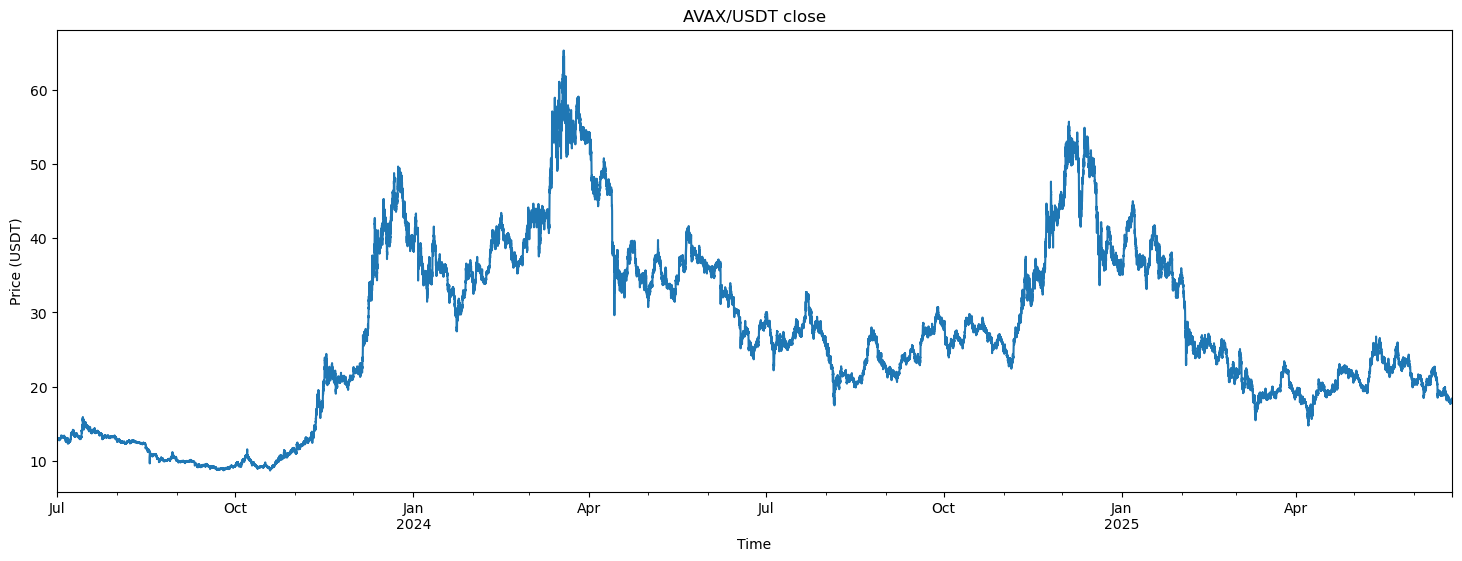

In [34]:
ax = backtest_bars.set_index("timestamp")["close"].plot(figsize=(18, 6))
ax.set(title="AVAX/USDT close", xlabel="Time", ylabel="Price (USDT)")
plt.show()